# Rays and waves in an eye aberrometer: a Shack-Hartmann sensor behind a schematic eye

Clinical aberrometers measure the wavefront that leaves the eye: a near
infrared laser puts a small spot onto the retina, the light scattered back
leaves the eye through the pupil carrying the aberrations of cornea and
lens, a relay images the pupil onto a Shack-Hartmann sensor, and the spot
displacements behind its lenslets give the wavefront slopes. From them the
instrument computes Zernike coefficients and the refraction (sphere,
cylinder, axis). Liang et al. (1994) built the first such aberrometer;
today it is routine before refractive surgery and for keratoconus.

The chain mixes rays and waves:

| part | description |
|---|---|
| retinal beacon (840 nm) | a point source in the vitreous |
| schematic eye (Escudero-Sanz & Navarro) | rays: aspheric cornea and lens, iris |
| 4f relay (two ideal lenses, f = 50 mm) | rays: images the pupil onto the lenslets |
| lenslet array (20 × 20, 0.4 mm, f = 16 mm) | **wave**: Fraunhofer spots, finite windows |
| reconstruction | slopes → Zernikes → refraction |

The ray trace gives the wavefront on the lenslets exactly (its optical
path lengths); `pyoptics.raywave.rays_to_field()` turns the rays into the
complex field that `pyoptics.shack_hartmann` needs for the spots. The
notebook compares the wavefront the rays carry with what the sensor
measures, for a normal eye, a myopic eye and an eye with a keratoconus,
and shows where the sensor runs out of dynamic range. It sacrifices
exactness for illustration: the beacon is a point (no double pass through
the eye, no speckle), the eye has no dispersion (the indices of the model
are used at 840 nm), and the lenslet spots are scalar Fraunhofer patterns
without crosstalk between neighbouring lenslets.

1. the eye and the relay,
2. rays → wavefront and field on the lenslets,
3. the lenslet spots (waves),
4. slopes, Zernikes, refraction: sensor vs. rays,
5. dynamic range: how much myopia the sensor can take.

Run time: about a minute.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.colors import ListedColormap

from pyoptics.raytrace import System, Surface, IdealLens, ZernikeSurface
from pyoptics.raywave import rays_to_field
from pyoptics.shack_hartmann import ShackHartmann
from pyoptics.bases import fringe_zernike
from pyoptics.propagators import rayleigh_sommerfeld_I_TF

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
t = np.linspace(0, 1, 256)[:, None]
LIGHT = ListedColormap(1 - (1 - colormaps["magma_r"](t[:, 0])[:, :3])*np.clip(t/0.15, 0, 1),
                       name="light")
t_start = time.time()

um = 1e-3                     # lengths in mm
WL = 0.84e-3                  # superluminescent diode of the aberrometer
N_CORNEA, N_AQUEOUS, N_LENS, N_VITREOUS = 1.3777, 1.3391, 1.4222, 1.3377
VITREOUS = 16.3203            # lens to retina
IRIS = 3.0                    # iris radius: a 6 mm pupil
F_RELAY = 50.0


def eye(axial=0.0, cornea=None):
    """Escudero-Sanz & Navarro eye, reversed: from the retina out through the cornea.

    axial: extra axial length (mm, > 0 myopic); cornea: Fringe Zernike sag
    coefficients (mm) on the anterior cornea, normalized to a 4 mm radius.
    The last surface (anterior cornea) gets the distance to the relay.
    """
    front = dict(R=-7.72, conic=-0.26, n_after=1.0, semi_diameter=6.0, label="cornea")
    return [Surface(6.0, 4.0, conic=-1.0, n_after=N_LENS, semi_diameter=5.0, label="lens"),
            Surface(-10.2, 0.0, conic=-3.1316, n_after=N_AQUEOUS, semi_diameter=5.0),
            Surface(np.inf, 3.05, semi_diameter=IRIS, label="iris"),
            Surface(-6.5, 0.55, n_after=N_CORNEA, semi_diameter=6.0),
            ZernikeSurface(thickness=0.0, zernike=cornea, norm_radius=4.0, **front)
            if cornea else Surface(thickness=0.0, **front)]


def aberrometer(axial=0.0, cornea=None):
    """Eye + 4f relay that images the eye's pupil onto the lenslets (last surface)."""
    surfaces = eye(axial, cornea)
    alone = System(surfaces, 2, WL, object_distance=VITREOUS + axial, object_height=0.0,
                   n_object=N_VITREOUS)
    pupil_z = alone.paraxial().xp_z          # the pupil seen from outside, behind the cornea
    surfaces[-1].thickness = pupil_z - alone.vertex_z[-1] + F_RELAY
    surfaces += [IdealLens(F_RELAY, thickness=2*F_RELAY, semi_diameter=15.0),
                 IdealLens(F_RELAY, thickness=F_RELAY, semi_diameter=15.0, label="lenslets")]
    return System(surfaces, 2, WL, object_distance=VITREOUS + axial, object_height=0.0,
                  n_object=N_VITREOUS)


sh = ShackHartmann(20, 0.4, 16.0, WL, pixels=48, samples=48, pupil_radius=3.3)
R_SH = sh.pupil_radius

EYES = {"normal": {}, "myopic (+1 mm axial length)": dict(axial=1.0),
        "keratoconus": dict(cornea={5: 0.004, 8: 0.016})}

## 1. The eye and the relay

The Escudero-Sanz & Navarro wide-angle schematic eye has a conic anterior
cornea, a conic crystalline lens with a homogeneous index, and the iris at
the front of the lens. Traced backwards, the retinal beacon is the object
in the vitreous, 16.32 mm behind the lens; the rays leave through the
cornea. A 4f relay of two 50 mm lenses images the eye's pupil (the image of
the iris through the cornea, the entrance pupil of the eye) onto the
lenslet array with magnification −1. The eye's pupil sits about 3 mm
behind the corneal vertex, and the cornea magnifies the 6 mm iris to a
6.8 mm pupil (paraxially; the real rim rays reach a radius of 3.33 mm),
so the beam fills a circle of radius 3.3 mm on the 8 mm lenslet array.

cornea vertex at z = 7.60 mm, pupil at z = 4.56 mm, pupil radius 3.40 mm


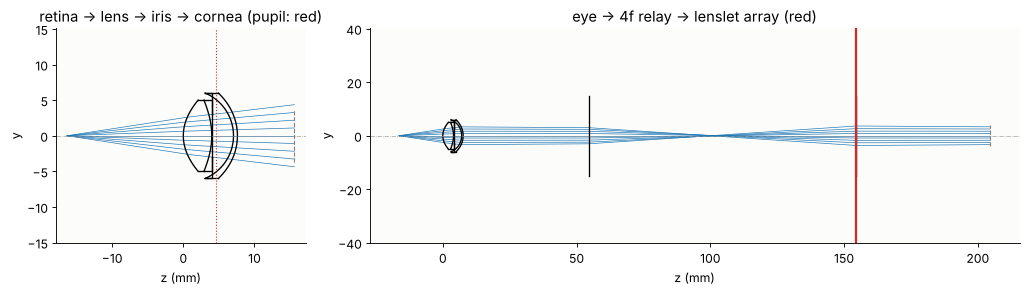

In [2]:
ab = aberrometer()
alone = System(eye(), 2, WL, object_distance=VITREOUS, object_height=0.0, n_object=N_VITREOUS)
p = alone.paraxial()
print("cornea vertex at z = {:.2f} mm, pupil at z = {:.2f} mm, pupil radius {:.2f} mm"
      .format(alone.vertex_z[-1], p.xp_z, p.xp_radius))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 2.6]})
show = System(eye()[:-1] + [Surface(R=-7.72, thickness=8.0, conic=-0.26, semi_diameter=6.0)],
              2, WL, object_distance=VITREOUS, object_height=0.0, n_object=N_VITREOUS)
show.draw(ax=axes[0], fields=[0.0], n_rays=9, lw=0.6)
axes[0].axvline(p.xp_z, color="C3", ls=":", lw=1)
axes[0].set_title("retina → lens → iris → cornea (pupil: red)")
ab.draw(ax=axes[1], fields=[0.0], n_rays=9, lw=0.6)
axes[1].axvline(ab.vertex_z[-1], color="C3", lw=2)
axes[1].set_title("eye → 4f relay → lenslet array (red)")
for ax in axes:
    ax.set_xlabel("z (mm)")
plt.tight_layout()

## 2. Rays → wavefront and field on the lenslets

Rays from the beacon on a polar grid over the iris arrive at the lenslets
with their optical path lengths: the wavefront. A Fringe Zernike fit to
these path lengths on the 3.3 mm circle is the "truth" the sensor should
find. `rays_to_field()` then sums the ray tubes into the complex field on
the sample grid of the sensor (48 samples per lenslet): amplitude from the
ray density, phase from the path lengths. The relay flips the pupil, so
x and y on the lenslets are −x and −y at the eye; even aberrations
(defocus, astigmatism, spherical aberration) do not care, the sign of coma
does.

The keratoconus is modelled as a Zernike deformation of the anterior cornea:
16 µm of vertical coma sag (the cone below the centre) and 4 µm of
astigmatism, both on a 4 mm radius.

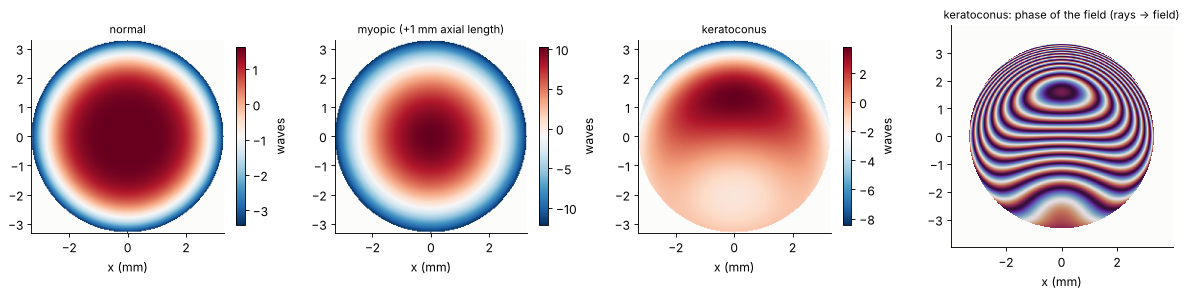

In [3]:
def rays_on_lenslets(system, n_r=80, n_phi=160):
    rho, phi = np.linspace(0, 1, n_r), np.linspace(0, 2*np.pi, n_phi + 1)
    RHO, PHI = np.meshgrid(rho, phi)
    px, py = RHO*np.cos(PHI), RHO*np.sin(PHI)
    px[-1], py[-1] = px[0], py[0]                     # close the polar grid
    b = system.trace_pupil(0.0, px.ravel(), py.ravel())
    shape = px.shape
    return (b.points[-1].reshape(shape + (3,)), b.directions[-1].reshape(shape + (3,)),
            b.opl[-1].reshape(shape), np.stack([px, py], -1))


def zernike_fit(P, S, n=15):
    """Fringe Zernikes (waves) of the path lengths S at the ray points P (r < R_SH)."""
    x, y, s = P[..., 0].ravel(), P[..., 1].ravel(), S.ravel()
    inside = np.isfinite(s) & (x**2 + y**2 <= R_SH**2)
    A = np.stack([fringe_zernike(j, x[inside]/R_SH, y[inside]/R_SH) for j in range(1, n + 1)], 1)
    c = np.linalg.lstsq(A, s[inside]/WL, rcond=None)[0]
    c[0] = 0.0                                          # piston
    return dict(zip(range(1, n + 1), c))


def wavefront_map(z, x):
    X, Y = np.meshgrid(x, x)
    W = sum(c*fringe_zernike(j, X/R_SH, Y/R_SH) for j, c in z.items())
    return np.where(X**2 + Y**2 <= R_SH**2, W, np.nan)


truth, fields = {}, {}
for name, kw in EYES.items():
    P, D, S, launch = rays_on_lenslets(aberrometer(**kw))
    truth[name] = zernike_fit(P, S)
    fields[name] = rays_to_field(sh.x, sh.y, P, D, S, WL, launch=launch)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
x_map = np.linspace(-R_SH, R_SH, 201)
for ax, (name, z) in zip(axes, truth.items()):
    zz = {j: c for j, c in z.items() if j > 3}           # without tilts
    im = ax.imshow(wavefront_map(zz, x_map), extent=[-R_SH, R_SH, -R_SH, R_SH], cmap="RdBu_r")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("x (mm)")
    plt.colorbar(im, ax=ax, shrink=0.8, label="waves")
u = fields["keratoconus"]
ax = axes[3]
ax.imshow(np.where(np.abs(u) > 0, np.angle(u), np.nan), cmap="twilight",
          extent=[sh.x[0], sh.x[-1], sh.y[0], sh.y[-1]], interpolation="nearest")
ax.set_title("keratoconus: phase of the field (rays → field)", fontsize=10)
ax.set_xlabel("x (mm)")
plt.tight_layout()

Without tilts, the normal eye shows defocus and the spherical aberration
of the eye (−0.9 waves of Fringe Z9 over the 6.7 mm pupil); the myopic eye
adds about 9 waves of defocus; the keratoconus adds vertical coma and
astigmatism. The field on the lenslets is a nearly uniform disk (the ray
density hardly changes), and its phase is the wavefront, tilts included,
wrapped into fringes of one wave.

## 3. The lenslet spots: waves

Each lenslet of 0.4 mm focuses its part of the field to a spot on the
camera 16 mm behind. Rays would make a point for a flat wavefront; the
spot is a diffraction pattern of the square lenslet, a sinc² with its
first zeros ±λf/p = ±34 µm from the centre, sampled by 48 pixels of
8.3 µm per lenslet. The Fresnel number p²/(4λf) = 3 of a lenslet is
small: the spot size is set by diffraction, not by the wavefront
curvature over the lenslet. Light that leaves the 0.4 mm window of a
lenslet is lost, so the maximum measurable slope is p/(2f) = 12.5 mrad.

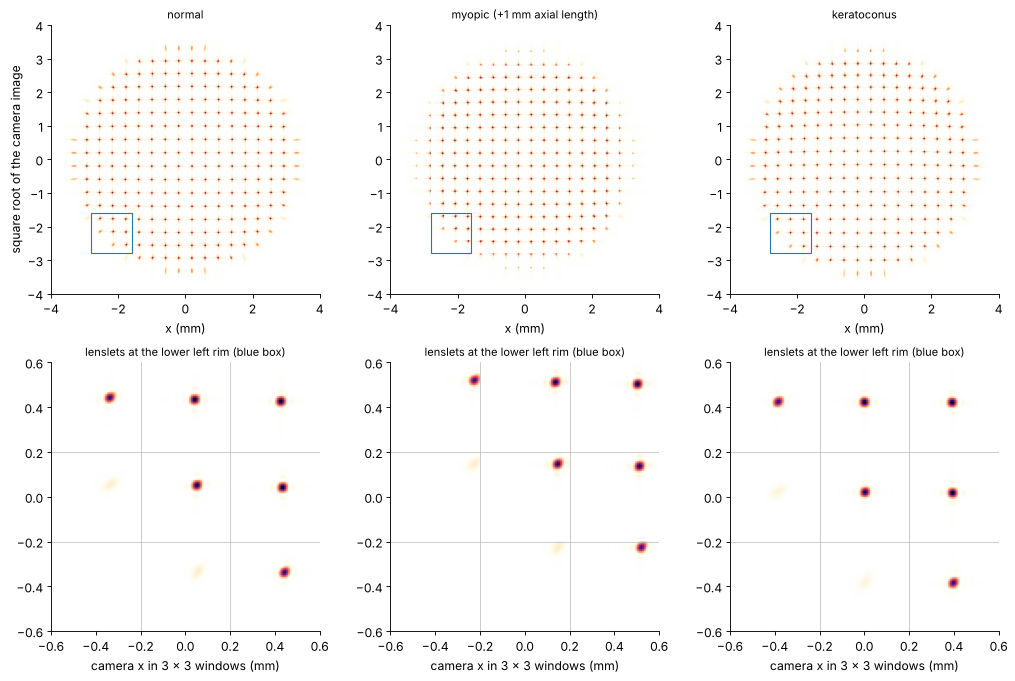

In [4]:
images = {name: sh.spots(u) for name, u in fields.items()}
ref = sh.spots(sh.field())                                  # plane wave: calibration
q = sh.pixels
fig, axes = plt.subplots(2, 3, figsize=(13, 8.6))
for col, (name, img) in enumerate(images.items()):
    ax = axes[0, col]
    ax.imshow(np.sqrt(img), cmap=LIGHT, extent=[-4, 4, -4, 4])
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("x (mm)")
    ax.add_patch(plt.Rectangle((-2.8, -2.8), 1.2, 1.2, fill=False, ec="C0"))
    ax = axes[1, col]
    ax.imshow(img[3*q:6*q, 3*q:6*q], cmap=LIGHT, extent=[-0.6, 0.6, -0.6, 0.6])
    for e in (-0.2, 0.2):
        ax.axvline(e, color="0.7", lw=0.6)
        ax.axhline(e, color="0.7", lw=0.6)
    ax.set_title("lenslets at the lower left rim (blue box)", fontsize=10)
    ax.set_xlabel("camera x in 3 × 3 windows (mm)")
axes[0, 0].set_ylabel("square root of the camera image")
plt.tight_layout()

At the rim, the defocus of the myopic eye pushes the spots towards the
window edges, and the outermost lenslets are only partly lit: the
reconstruction drops lenslets with less than half the flux of the
brightest one. The keratoconus spots are shifted asymmetrically.

## 4. Slopes, Zernikes, refraction: sensor vs. rays

The centroids relative to the calibration spots, divided by the lenslet
focal length, are the mean wavefront slopes over each lenslet.
`reconstruct_zernikes()` fits the gradients of the first 15 Fringe
Zernikes to them (modal reconstruction). The refraction follows from the
second-order Zernikes (Thibos et al. 2004), here with the sign convention
of the phase in pyoptics (a converging beam, a myopic eye, has negative
defocus) and the radius R = 3.3 mm of the pupil on the lenslets:

- spherical equivalent M = 4 λ a₄/R² (Fringe a₄ = √3 c₂⁰ of the OSA standard),
- cylinder components J₀ = 2 λ a₅/R², J₄₅ = 2 λ a₆/R²,
- minus cylinder C = −2 √(J₀² + J₄₅²), sphere S = M − C/2.

The "Zernike" refraction depends on the pupil size through the spherical
aberration (the ρ² part of Z9 is balanced by Z4). The paraxial refraction
uses the ρ² terms of Z4 and Z9 together, M_par = 4 λ (a₄ − 3 a₉)/R².

In [5]:
measured, slopes_all = {}, {}
for name, img in images.items():
    s = sh.slopes(img, reference=ref)
    slopes_all[name] = s
    measured[name] = sh.reconstruct_zernikes(s, 15)


def refraction(z):
    M = 4*WL*z[4]/R_SH**2*1e3                    # 1/mm → diopters
    J0, J45 = 2*WL*z[5]/R_SH**2*1e3, 2*WL*z[6]/R_SH**2*1e3
    C = -2*np.hypot(J0, J45)
    axis = 180 - (-np.degrees(0.5*np.arctan2(J45, J0))) % 180   # in (0, 180]
    return M - C/2, C, axis, M, 4*WL*(z[4] - 3*z[9])/R_SH**2*1e3


print("{:30s} {:>8s} {:>24s} {:>8s} {:>9s}".format("", "", "sphere / cyl × axis", "M (D)",
                                                     "M_par (D)"))
for name in EYES:
    for label, z in (("rays", truth[name]), ("sensor", measured[name])):
        S_, C, axis, M, Mp = refraction(z)
        cyl = "{:+.2f} × {:3.0f}°".format(C, axis) if abs(C) >= 0.01 else "  0.00       "
        print("{:30s} {:>8s} {:>+10.2f} / {} {:>+8.2f} {:>+9.2f}"
              .format(name if label == "rays" else "", label, S_, cyl, M, Mp))

                                             sphere / cyl × axis    M (D) M_par (D)
normal                             rays      -0.78 /   0.00           -0.78     +0.06
                                 sensor      -0.77 /   0.00           -0.77     +0.14
myopic (+1 mm axial length)        rays      -3.45 /   0.00           -3.45     -2.56
                                 sensor      -3.44 /   0.00           -3.44     -2.54
keratoconus                        rays      -0.59 / -0.36 × 180°    -0.77     +0.05
                                 sensor      -0.59 / -0.36 ×   0°    -0.77     +0.13


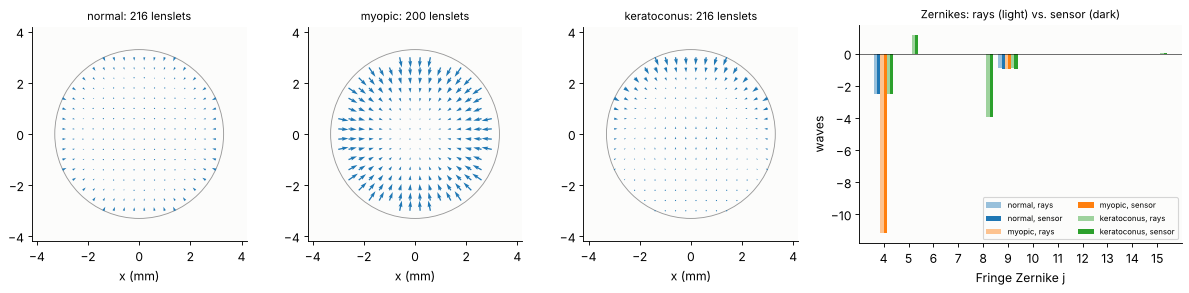

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 1, 1, 1.5]})
yc = (np.arange(sh.n_lenslets) - (sh.n_lenslets - 1)/2)*sh.pitch
XC, YC = np.meshgrid(yc, yc)
for ax, (name, s) in zip(axes, slopes_all.items()):
    ax.add_patch(plt.Circle((0, 0), R_SH, fill=False, color="0.6", lw=0.8))
    ax.quiver(XC[s.valid], YC[s.valid], s.sx[s.valid], s.sy[s.valid], color="C0",
              angles="xy", scale_units="xy", scale=0.012/0.4, width=0.006)
    ax.set_xlim(-4.2, 4.2), ax.set_ylim(-4.2, 4.2)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title("{}: {} lenslets".format(name.split(" (")[0], s.valid.sum()), fontsize=10)
    ax.set_xlabel("x (mm)")
ax = axes[3]
js = np.arange(4, 16)
w = 0.13
for i, name in enumerate(EYES):
    ax.bar(js + (i - 1)*2*w - w/2, [truth[name][j] for j in js], w, color="C%d" % i,
           alpha=0.45, label=name.split(" (")[0] + ", rays")
    ax.bar(js + (i - 1)*2*w + w/2, [measured[name][j] for j in js], w, color="C%d" % i,
           label=name.split(" (")[0] + ", sensor")
ax.set_xticks(js)
ax.set_xlabel("Fringe Zernike j")
ax.set_ylabel("waves")
ax.axhline(0, color="k", lw=0.5)
ax.legend(fontsize=7, ncol=2)
ax.set_title("Zernikes: rays (light) vs. sensor (dark)", fontsize=10)
plt.tight_layout()

The sensor reproduces the Zernikes of the ray trace to a few hundredths of
a wave in defocus, astigmatism and coma, and the Zernike refraction to
0.01 D. The largest difference is in the spherical aberration Z9 (≈ 0.07
waves): a lenslet averages the slope over 0.4 mm, while the steep ρ⁴ term
changes fastest at the rim, where the lenslets are cut by the pupil edge.
Through Z9 this shifts the paraxial refraction by 0.08 D.
The 0.8 D of "Zernike myopia" of the normal eye is the spherical
aberration of the 6.7 mm pupil, not a refractive error: the paraxial
refraction is almost zero (the model eye is emmetropic for paraxial rays).
One millimetre of extra axial length makes about −2.7 D.

## 5. Dynamic range: how much myopia the sensor can take

A defocus of M diopters tilts the wavefront at the pupil rim by M R. For
the rim spot to stay in its window, M R must stay below p/(2f) = 12.5 mrad,
minus the half width of the spot: about ±3 D on the 3.3 mm pupil.

What happens beyond depends on a wave effect the window model of
`ShackHartmann.spots()` leaves out: a spot that leaves its window lands in
the neighbouring one. To see it, we propagate the whole field: the
lenslet array as a thin phase element exp(−ik r²/(2f)) about each lenslet
centre, then the angular spectrum over the 16 mm to the camera. The
samples of the field coincide with the camera pixels (8.3 µm), so the
image goes straight into `slopes()`. We lengthen and shorten the eye in
steps of 0.5 mm and compare the paraxial refraction of the rays with
both sensor models.

axial (mm)   rays (D)  windows (D)  camera (D)   valid lenslets (windows, camera)
  -3.0        +9.78       +9.72       -1.68      (36, 216)
  -2.5        +7.93       +7.89       +3.24      (64, 212)
  -2.0        +6.18       +6.23      +10.26      (152, 208)
  -1.5        +4.53       +4.59       +4.59      (216, 216)
  -1.0        +2.96       +3.03       +3.02      (216, 216)
  -0.5        +1.48       +1.55       +1.54      (216, 216)
  +0.0        +0.06       +0.14       +0.13      (216, 216)
  +0.5        -1.28       -1.20       -1.22      (216, 208)
  +1.0        -2.56       -2.54       -2.58      (200, 192)
  +1.5        -3.79       -3.79       -7.25      (144, 112)
  +2.0        -4.95       -4.97       -4.57      (100, 20)
  +2.5        -6.07       -6.19       -6.02      (88, 72)
  +3.0        -7.14       -7.18       -3.95      (64, 36)


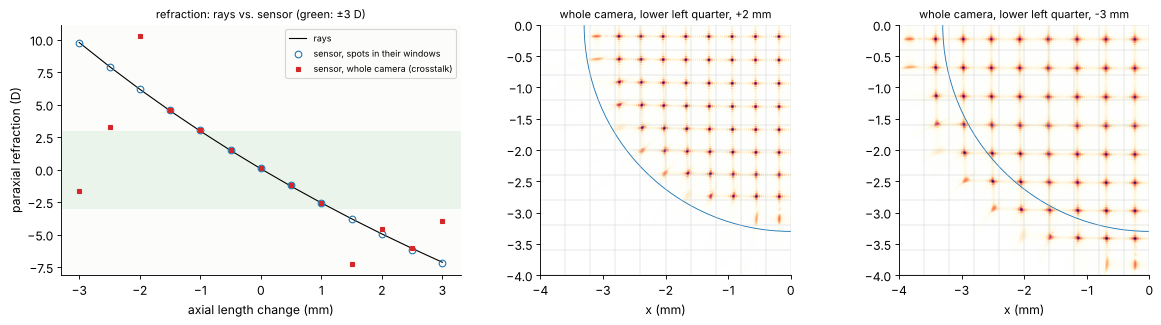

In [7]:
pad = 160
N = len(sh.x)
x_cam = (np.arange(N + 2*pad) - (N + 2*pad - 1)/2)*(sh.x[1] - sh.x[0])
local = sh.x - (np.floor(sh.x/sh.pitch) + 0.5)*sh.pitch       # relative to the lenslet centre
LX, LY = np.meshgrid(local, local)
LENSLETS = np.exp(-1j*2*np.pi/WL*(LX**2 + LY**2)/(2*sh.focal_length))


def camera(u):
    """Whole-camera image: lenslet phases, angular spectrum over f, crosstalk included."""
    E = rayleigh_sommerfeld_I_TF(np.pad(u*LENSLETS, pad), x_cam, x_cam, sh.focal_length, WL)[0]
    return np.abs(E[pad:-pad, pad:-pad])**2/np.sum(np.abs(u)**2)


ref_cam = camera(sh.field())
axials = np.arange(-3.0, 3.01, 0.5)
result = {"rays": [], "windows": [], "whole camera": []}
n_valid, cam_images = [], {}
for a in axials:
    P, D, S, launch = rays_on_lenslets(aberrometer(axial=a))
    u = rays_to_field(sh.x, sh.y, P, D, S, WL, launch=launch)
    result["rays"].append(refraction(zernike_fit(P, S))[4])
    s = sh.slopes(sh.spots(u), reference=ref)
    result["windows"].append(refraction(sh.reconstruct_zernikes(s, 15))[4])
    img = camera(u)
    cam_images[a] = img
    s_cam = sh.slopes(img, reference=ref_cam)
    result["whole camera"].append(refraction(sh.reconstruct_zernikes(s_cam, 15))[4])
    n_valid.append((int(s.valid.sum()), int(s_cam.valid.sum())))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax = axes[0]
ax.plot(axials, result["rays"], "k-", lw=1, label="rays")
ax.plot(axials, result["windows"], "o", color="C0", ms=6, mfc="none",
        label="sensor, spots in their windows")
ax.plot(axials, result["whole camera"], "s", color="C3", ms=4,
        label="sensor, whole camera (crosstalk)")
ax.axhspan(-3, 3, color="C2", alpha=0.08, lw=0)
ax.set_xlabel("axial length change (mm)")
ax.set_ylabel("paraxial refraction (D)")
ax.legend(fontsize=8, loc="upper right")
ax.set_title("refraction: rays vs. sensor (green: ±3 D)", fontsize=10)
for ax, a in zip(axes[1:], (1.5, -3.0)):
    ax.imshow(np.sqrt(cam_images[a][: 10*sh.pixels, : 10*sh.pixels]), cmap=LIGHT,
              extent=[-4, 0, -4, 0])
    for e in np.arange(-4, 0.01, 0.4):
        ax.axvline(e, color="0.8", lw=0.4)
        ax.axhline(e, color="0.8", lw=0.4)
    ax.add_patch(plt.Circle((0, 0), R_SH, fill=False, color="C0", lw=0.8))
    ax.set_title("whole camera, lower left quarter, {:+.0f} mm".format(a), fontsize=10)
    ax.set_xlabel("x (mm)")
plt.tight_layout()

print("axial (mm)   rays (D)  windows (D)  camera (D)   valid lenslets (windows, camera)")
for k, a in enumerate(axials):
    print("{:+6.1f}      {:+7.2f}     {:+7.2f}     {:+7.2f}      {}"
          .format(a, result["rays"][k], result["windows"][k], result["whole camera"][k],
                  n_valid[k]))

From −2.6 D to +4.6 D (axial length −1.5 to +1 mm), the rays and both
sensor models agree to better than 0.1 D. Beyond that the two sensor models part:

- With each spot confined to its own window, the rim spots leave their
  windows and their light is lost; those lenslets drop out, and the
  reconstruction carries on with the inner ones. Its numbers stay
  right, but over a shrinking part of the pupil (36 of 216 lenslets at
  +9.8 D).
- On the whole camera, the rim spots land in the neighbouring windows
  (right panels: spots outside the blue pupil circle, two spots in one
  window). The sensor assigns them to the wrong lenslets, keeps those
  lenslets as valid and reports refractions that are wrong by several
  diopters. This is the real failure of a Shack-Hartmann sensor, and the
  reason why clinical aberrometers first null the spherical error with a
  Badal optometer or a movable relay lens, or use spot tracking
  algorithms that follow the spots across window borders.

The range is asymmetric: the eye's positive spherical aberration adds to
the rim slopes of a myopic eye and subtracts from those of a hyperopic
one. Longer lenslet focal lengths make the sensor more sensitive (f per
unit slope) and its range p/(2f) smaller.

## Summary

- The ray trace through the schematic eye gives the wavefront on the
  lenslets, and with `rays_to_field()` the complex field the
  Shack-Hartmann model needs; the "ray truth" is a Zernike fit to the
  optical path lengths.
- The lenslet spots are waves: their width λf/p, the windows and the
  partly lit rim lenslets set the sensitivity and the dynamic range.
- Inside its range, the sensor reproduces the ray-traced Zernikes and the
  refraction to about 0.01 D; spherical aberration is reproduced less well
  because the lenslets average the slopes.
- Outside, the spots cross into the neighbouring windows, a wave effect
  that the window model hides: the measurement fails although the ray
  model of the eye has nothing special to report.

In [8]:
print("run time {:.0f} s".format(time.time() - t_start))

run time 53 s


## References

- J. Liang, B. Grimm, S. Goelz and J. F. Bille, "Objective measurement of wave aberrations of the human eye with the use of a Hartmann-Shack wave-front sensor", J. Opt. Soc. Am. A 11, 1949-1957 (1994).
- B. C. Platt and R. Shack, "History and principles of Shack-Hartmann wavefront sensing", J. Refract. Surg. 17, S573-S577 (2001).
- I. Escudero-Sanz and R. Navarro, "Off-axis aberrations of a wide-angle schematic eye model", J. Opt. Soc. Am. A 16, 1881-1891 (1999).
- R. Navarro, J. Santamaría and J. Bescós, "Accommodation-dependent model of the human eye with aspherics", J. Opt. Soc. Am. A 2, 1273-1281 (1985).
- L. N. Thibos, R. A. Applegate, J. T. Schwiegerling and R. Webb, "Standards for reporting the optical aberrations of eyes", J. Refract. Surg. 18, S652-S660 (2002).
- L. N. Thibos, X. Hong, A. Bradley and R. A. Applegate, "Accuracy and precision of objective refraction from wavefront aberrations", J. Vis. 4(4), 329-351 (2004).
- W. H. Southwell, "Wave-front estimation from wave-front slope measurements", J. Opt. Soc. Am. 70, 998-1006 (1980).
- D. A. Atchison and G. Smith, *Optics of the Human Eye*, Butterworth-Heinemann (2000).